# Chapter 3 — Cameras

Companion notebook to **Chapter 3** of the course notes. We project points with the pinhole model, play with lens
distortion, check the reprojection Jacobians, calibrate a simulated wide-angle camera with Zhang's method, and look
at stereo depth uncertainty.

Frames follow OpenCV: in the camera frame $z$ points forward, $x$ right, $y$ down. A camera pose is $T_{wc}$
(camera to world), and a world point is seen as $\mathbf q = T_{wc}^{-1}\mathbf p_w$.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import lie, calib
from vslam.camera import PinholeCamera, StereoCamera, look_at
from ch03_cameras import WIDE       # the wide-angle camera of Figure 3.1

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. Projecting a scene (Proposition 3.4)

A camera at 1.2 m height looks at a "garden" made of a ground grid and a fence. We project with `project_world` and
check the result against the projection matrix $P = K[R_{cw}\ \ \mathbf t_{cw}]$.

max |project - P p| = 2.2737367544323206e-13


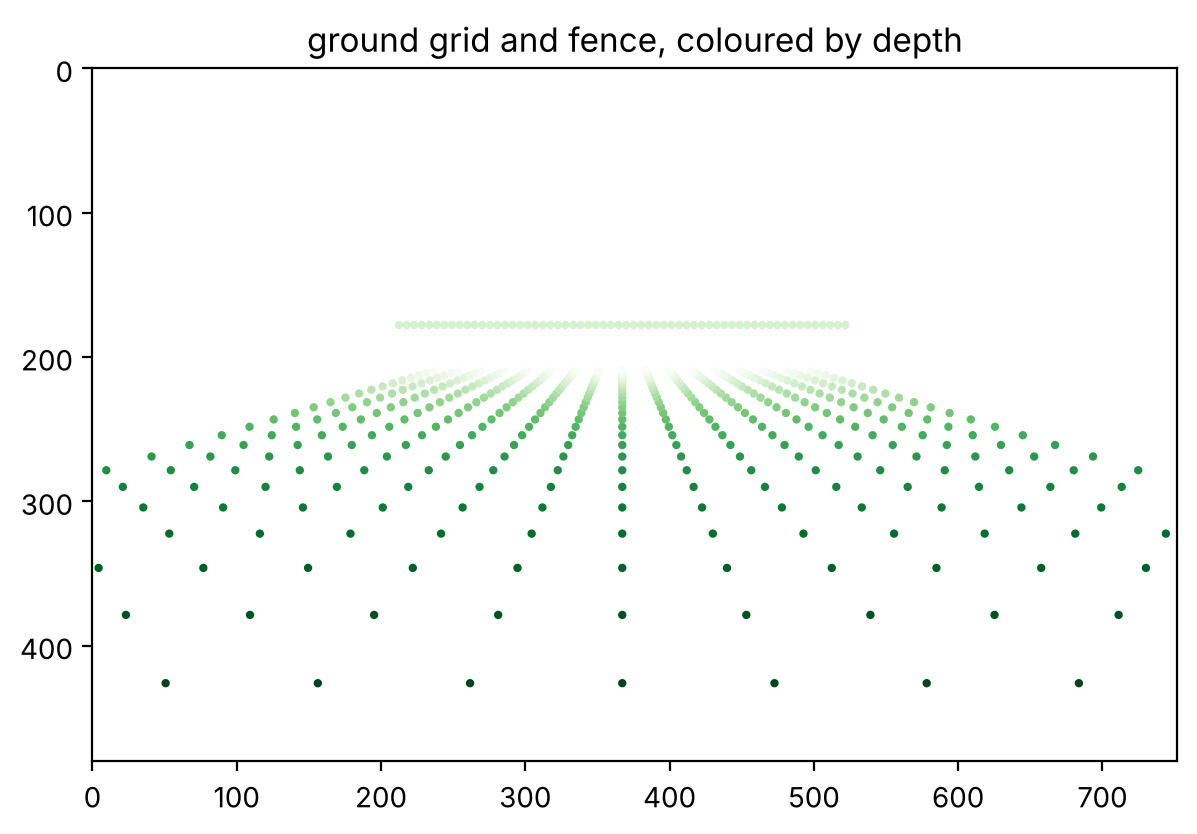

In [2]:
cam = PinholeCamera(458.7, 457.3, 367.2, 248.4, width=752, height=480)   # no distortion
T_wc = look_at(eye=np.array([0.0, -4.0, 1.2]), target=np.array([0.0, 3.0, 0.0]))

gx, gy = np.meshgrid(np.linspace(-4, 4, 17), np.linspace(-2, 10, 25))
ground = np.column_stack([gx.ravel(), gy.ravel(), np.zeros(gx.size)])
fence = np.column_stack([np.linspace(-4, 4, 60), np.full(60, 8.0), np.full(60, 1.0)])
pts = np.vstack([ground, fence])

T_cw = lie.se3_inv(T_wc)
q = pts @ T_cw[:3, :3].T + T_cw[:3, 3]
front = q[:, 2] > 0.1
u = cam.project(q[front])
ok = cam.in_image(u)

P = cam.K @ T_cw[:3, :]
h = np.column_stack([pts[front], np.ones(front.sum())]) @ P.T
print("max |project - P p| =", np.abs(u - h[:, :2] / h[:, 2:]).max())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(*u[ok].T, s=4, c=q[front][ok, 2], cmap="Greens_r")
ax.set_xlim(0, cam.width); ax.set_ylim(cam.height, 0); ax.set_aspect("equal")
ax.set_title("ground grid and fence, coloured by depth");

## 2. Lens distortion and undistortion (Definition 3.6, Proposition 3.7)

`undistort` inverts the distortion map by Newton's method. We check the round trip across the whole image of the
wide-angle camera, and count Newton iterations.

max round-trip error |d(d^-1(x_d)) - x_d| : 8.715250743307479e-15


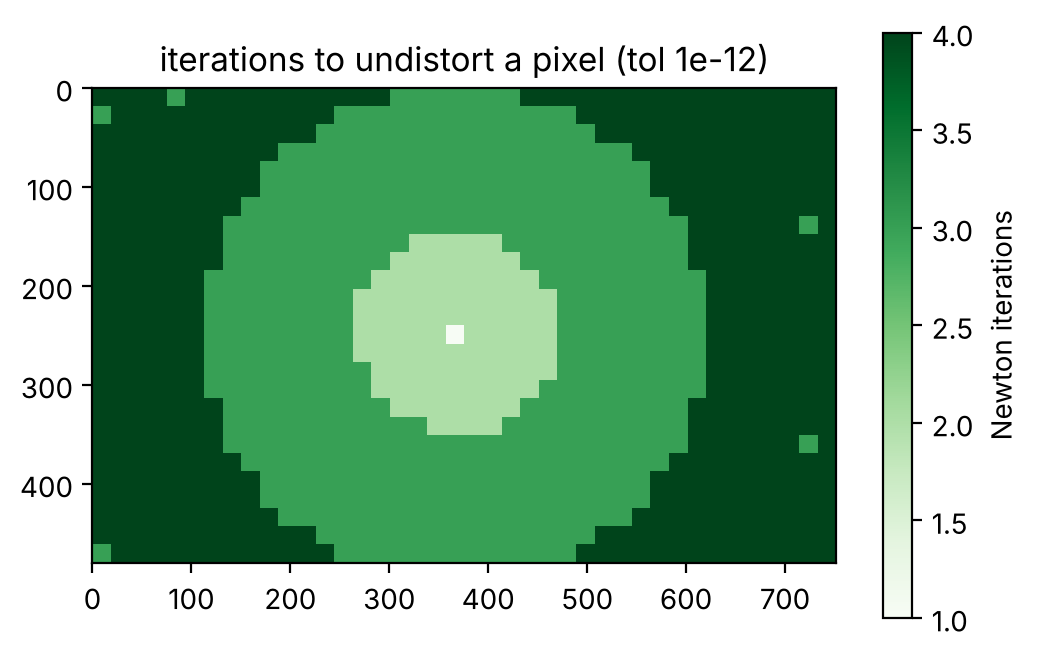

In [3]:
us, vs = np.meshgrid(np.linspace(0, WIDE.width, 40), np.linspace(0, WIDE.height, 26))
xd = np.column_stack([(us.ravel() - WIDE.cx) / WIDE.fx, (vs.ravel() - WIDE.cy) / WIDE.fy])
x = np.array([WIDE.undistort(p) for p in xd])
print("max round-trip error |d(d^-1(x_d)) - x_d| :", np.abs(WIDE.distort(x) - xd).max())

def newton_steps(cam, xd, tol=1e-12):
    x = xd.copy()
    for k in range(50):
        r = cam.distort(x) - xd
        if np.linalg.norm(r) < tol:
            return k
        x = x - np.linalg.solve(cam.distort_jacobian(x), r)
    return 50

steps = np.array([newton_steps(WIDE, p) for p in xd]).reshape(us.shape)
fig, ax = plt.subplots(figsize=(6, 3.8))
im = ax.imshow(steps, extent=[0, WIDE.width, WIDE.height, 0], cmap="Greens")
fig.colorbar(im, ax=ax, label="Newton iterations")
ax.set_title("iterations to undistort a pixel (tol 1e-12)");

## 3. The reprojection Jacobians (Proposition 3.8)

Three ways to compute $\partial\mathbf u/\partial\boldsymbol\xi$: the code (general chain rule, here without
distortion), the explicit matrix (3.2), and central finite differences.

In [4]:
p = np.array([0.5, 2.0, 0.3])
u0, J_code, J_p = cam.project_world(T_wc, p)

X, Y, Z = lie.se3_act(lie.se3_inv(T_wc), p)
x, y, fx, fy = X / Z, Y / Z, cam.fx, cam.fy
J_explicit = np.array([[-fx / Z, 0, fx * x / Z, fx * x * y, -fx * (1 + x * x), fx * y],
                       [0, -fy / Z, fy * y / Z, fy * (1 + y * y), -fy * x * y, -fy * x]])

eps = 1e-6
J_num = np.column_stack([(cam.project_world(T_wc @ lie.se3_exp(e), p)[0]
                          - cam.project_world(T_wc @ lie.se3_exp(-e), p)[0]) / (2 * eps)
                         for e in eps * np.eye(6)])
print("|code - explicit| =", np.abs(J_code - J_explicit).max())
print("|code - numeric|  =", np.abs(J_code - J_num).max())

|code - explicit| = 5.684341886080802e-14
|code - numeric|  = 1.85595467883104e-08


**Near and far features.** How far does a pixel move for a 1 cm sideways translation of the camera, and for a
1 mrad yaw? The first falls like $1/Z$; the second does not depend on $Z$ (the *In words* box after Proposition 3.8).

In [5]:
depths = np.array([1, 2, 5, 10, 20, 50.0])
d_trans, d_rot = [], []
for Zd in depths:
    p_cam = np.array([0.0, 0.0, Zd])                    # straight ahead
    p_w = lie.se3_act(T_wc, p_cam)
    _, J, _ = cam.project_world(T_wc, p_w)
    d_trans.append(np.linalg.norm(J @ np.array([0.01, 0, 0, 0, 0, 0])))
    d_rot.append(np.linalg.norm(J @ np.array([0, 0, 0, 0, 1e-3, 0])))
print(f"{'Z [m]':>6} {'1 cm sideways [px]':>20} {'1 mrad yaw [px]':>17}")
for Zd, a, b in zip(depths, d_trans, d_rot):
    print(f"{Zd:6.0f} {a:20.3f} {b:17.3f}")

 Z [m]   1 cm sideways [px]   1 mrad yaw [px]
     1                4.587             0.459
     2                2.293             0.459
     5                0.917             0.459
    10                0.459             0.459
    20                0.229             0.459
    50                0.092             0.459


## 4. Calibrating a simulated wide-angle camera (Section 3.4)

Ten views of a 9×6 checkerboard, 0.3 px noise. We estimate one homography per view with the normalised DLT, then
$K$ with Zhang's linear step, then each board pose. The lens has strong barrel distortion, which the linear step
ignores.

true K:
 [[458.7   0.  367.2]
 [  0.  457.3 248.4]
 [  0.    0.    1. ]]
estimated K (linear step, distortion ignored):
 [[489.04    -3.4296 371.1792]
 [  0.     486.8335 241.4323]
 [  0.       0.       1.    ]]


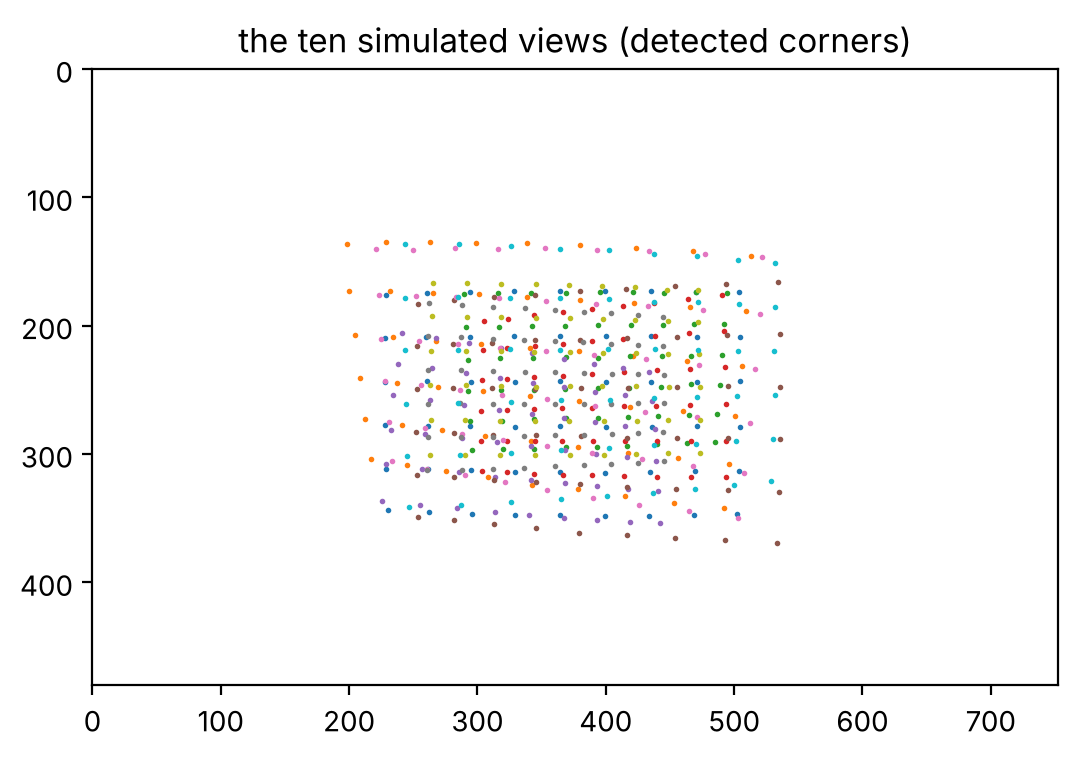

In [6]:
board, views = calib.synthetic_views(WIDE, 10, rng, noise=0.3)
Hs = [calib.homography_dlt(board[:, :2], u) for _, u in views]
K_hat = calib.zhang_intrinsics(Hs)
print("true K:\n", WIDE.K)
print("estimated K (linear step, distortion ignored):\n", K_hat)

fig, ax = plt.subplots(figsize=(6.5, 4))
for _, u in views:
    ax.plot(*u.T, ".", ms=2)
ax.set_xlim(0, WIDE.width); ax.set_ylim(WIDE.height, 0); ax.set_aspect("equal")
ax.set_title("the ten simulated views (detected corners)");

**Reprojection residuals.** Reproject every corner with the estimated $K$ and poses (pinhole, no distortion) and
plot observed − predicted, for 25 views spread over the whole image and 0.1 px noise. On the wide-angle lens
the residuals are about 3 px, thirty times the noise, and *systematic*: neighbouring corners of a view have similar
arrows, whereas noise would be independent from corner to corner. They are not a clean radial field, because each
view's estimated pose absorbs part of the distortion. Removing them is the job of the nonlinear refinement of
Chapter 4, which estimates the distortion together with $K$ and the poses. For comparison, the same pipeline on an
ideal lens leaves only the 0.1 px noise.

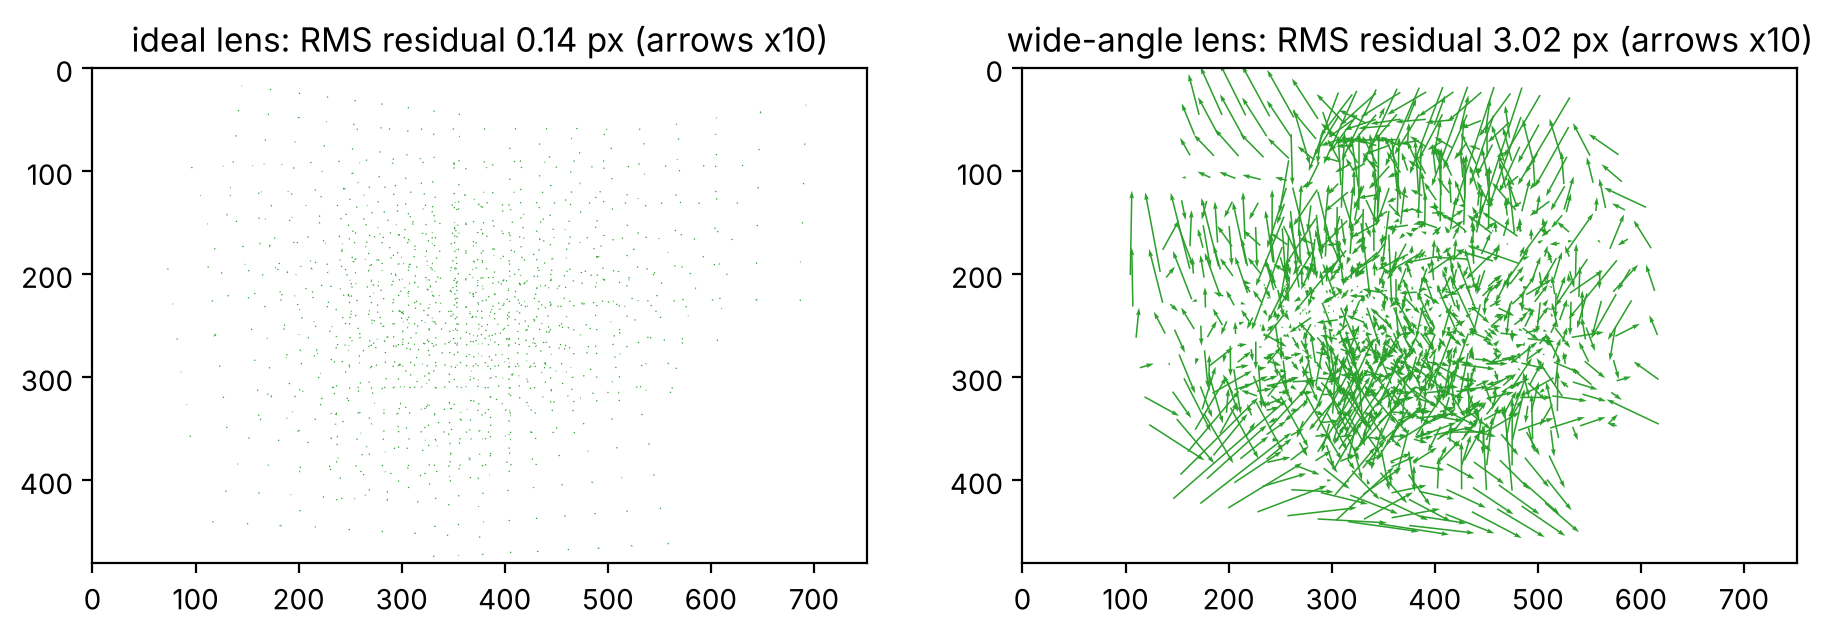

In [7]:
def residuals(cam_true, n_views=25, noise=0.1, seed=1):
    # spread=0.1 moves the board across the whole image, where distortion is strong
    board, views = calib.synthetic_views(cam_true, n_views, np.random.default_rng(seed), noise,
                                         distance=0.5, spread=0.1)
    Hs = [calib.homography_dlt(board[:, :2], u) for _, u in views]
    K = calib.zhang_intrinsics(Hs)
    pin = PinholeCamera(K[0, 0], K[1, 1], K[0, 2], K[1, 2])
    obs, res = [], []
    for (_, u), H in zip(views, Hs):
        T_cb = calib.zhang_extrinsics(K, H)
        pred = pin.project(board @ T_cb[:3, :3].T + T_cb[:3, 3])
        obs.append(u); res.append(u - pred)
    return np.vstack(obs), np.vstack(res)

ideal = PinholeCamera(WIDE.fx, WIDE.fy, WIDE.cx, WIDE.cy, width=WIDE.width, height=WIDE.height)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, c, title in [(ax[0], ideal, "ideal lens"), (ax[1], WIDE, "wide-angle lens")]:
    o, r = residuals(c)
    a.quiver(o[:, 0], o[:, 1], r[:, 0], r[:, 1], angles="xy", scale_units="xy", scale=0.1,
             color="tab:green", width=0.002)
    rms = np.sqrt(np.mean(np.sum(r**2, axis=1)))
    a.set_title(f"{title}: RMS residual {rms:.2f} px (arrows x10)")
    a.set_xlim(0, c.width); a.set_ylim(c.height, 0); a.set_aspect("equal")

## 5. Stereo depth (Proposition 3.16, Exercise 3.4)

In [8]:
cam_s = PinholeCamera(700.0, 700.0, 640.0, 360.0, width=1280, height=720)
sigma_d, Z = 0.25, 5.0
for b in [0.06, 0.12, 0.18, 0.30]:
    st = StereoCamera(cam_s, b)
    z, _ = st.project(np.array([0.0, 0.0, Z]))
    noisy = z + np.column_stack([np.zeros(20000), np.zeros(20000),
                                 rng.normal(scale=sigma_d, size=20000)])
    mc = np.std([st.triangulate(n)[2] for n in noisy])
    print(f"baseline {100*b:4.0f} cm: sigma_Z at 5 m = {st.depth_std(Z, sigma_d):.3f} m "
          f"(Monte Carlo {mc:.3f} m)")
print("baseline for 5 cm at 5 m (Exercise 3.4):", Z**2 * sigma_d / (700 * 0.05), "m")

baseline    6 cm: sigma_Z at 5 m = 0.149 m (Monte Carlo 0.149 m)
baseline   12 cm: sigma_Z at 5 m = 0.074 m (Monte Carlo 0.075 m)
baseline   18 cm: sigma_Z at 5 m = 0.050 m (Monte Carlo 0.049 m)
baseline   30 cm: sigma_Z at 5 m = 0.030 m (Monte Carlo 0.030 m)
baseline for 5 cm at 5 m (Exercise 3.4): 0.17857142857142858 m


## 6. Turning on the spot (Exercise 3.2)

Two cameras with the same centre and different orientations: every correspondence satisfies
$\tilde{\mathbf u}_2 \sim K R K^{-1}\tilde{\mathbf u}_1$, whatever the depth. The images carry no depth information.

In [9]:
c = np.array([0.0, 0.0, 1.2])
T1 = look_at(c, np.array([0.0, 5.0, 0.0]))
T2 = look_at(c, np.array([3.0, 4.0, 0.0]))          # same centre, mower turned
R = T2[:3, :3].T @ T1[:3, :3]                        # R_{c2 c1}
Hinf = cam.K @ R @ np.linalg.inv(cam.K)

for depth in [1.0, 5.0, 50.0]:
    p = lie.se3_act(T1, np.array([0.3, -0.1, depth]))
    u1, u2 = cam.project_world(T1, p)[0], cam.project_world(T2, p)[0]
    h = Hinf @ np.append(u1, 1.0)
    print(f"depth {depth:5.1f} m: |u2 - K R K^-1 u1| = {np.linalg.norm(u2 - h[:2] / h[2]):.2e} px")

depth   1.0 m: |u2 - K R K^-1 u1| = 1.66e-13 px
depth   5.0 m: |u2 - K R K^-1 u1| = 0.00e+00 px
depth  50.0 m: |u2 - K R K^-1 u1| = 1.08e-13 px


## 7. Try it yourself

* In section 4, use 3 views instead of 10 and increase the noise to 1 px. How stable is $\hat K$? Compare with Figure 3.2.
* Set the tangential coefficients of `WIDE` to $p_1 = 5\cdot10^{-3}$. How does the residual pattern of section 4 change?
* In section 3, move the point far away (depth 50 m). Which columns of the Jacobian vanish? What does it mean for
  estimating the mower's position from distant trees?